# Ramen on ImageNet-C: the baseline for the true-label cache experiment

**Question.** How well does Ramen do on ImageNet-C, per domain and across seeds? This notebook fixes the baseline and
the noise floor that the true-label cache oracle is compared against.

**The experiment this folder builds up to.** Ramen files every test image into the memory queue of its *zero-shot
prediction*, so every zero-shot error lands in the wrong class queue. The oracle `true_label` files each image under
its **true label** instead (it uses ground truth, so it is an upper bound, not a method). Everything else (stored
gradient, retrieval, weighting, step, reset) stays Ramen's. This notebook only covers the baseline.

**Runs in this notebook.**

| Run name | What it is | Uses true labels? |
|---|---|---|
| `NoAdapt` | CLIP zero-shot, no adaptation | no |
| `Ramen` | Ramen (cfg/ImageNetC5K/Ramen.yaml: capacity 75 per class, top-k 1, β 0, signSGD lr 0.01) | no |

**Data.** ImageNet-C, severity 5, the 5,000-image subset (`src/datasets/imagenet_test_image_ids.txt`) under each of
15 corruptions = 75,000 images. The same 5,000 images appear once per corruption. Labels cover 997 of the 1,000 classes.
All corruptions are mixed into one shuffled stream with batch size 100. Model: CLIP ViT-B/16, default 7-template prompt
ensemble. Here a *domain* is a corruption.

**Seeds.** A seed sets the stream order (which images arrive together and in what order). NoAdapt is identical for every seed.
Seed 0 is used for the per-domain analysis; seeds 0–4 of Ramen give the noise floor.

**How the runs were produced.** `exp.run(...)` in `new_experiments/ramen_analysis.py` through
`true_label_cache.TrueLabelCacheExperiment` (this folder), with the settings in its `DATASETS` (num_workers changes the stream order, so keep it).
Results are cached in `new_experiments/results/ImageNetC5K_<model>_mixed_nall_bs100_s<seed>_<run>.pkl`.
A missing run is computed on the GPU. Use `python run_true_label.py ImageNetC5K <seed>` for a detached run.

**What counts as a result.** A later variant's gain over Ramen counts only if it is above the **noise floor** = 2 × (max − min)
of Ramen's domain-averaged accuracy over seeds 0–4 (computed in section 4).

**How to read this notebook.** 1 Setup · 2 The data · 3 Sanity check of the new method · 4 Ramen results (per domain, over the stream, across seeds) ·
5 Interpretation · 6 Glossary. Accuracy is **domain-averaged** (mean of the per-domain accuracies) unless a table says *pooled*.

## 1. Setup

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')  # only used if a run is not cached

import matplotlib.pyplot as plt
import pandas as pd
from true_label_cache import TrueLabelCacheExperiment, seed_table, noise_floor, domain_avg

pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATASET, SEED, BY = 'ImageNetC5K', 0, 'domain'
exp = TrueLabelCacheExperiment(DATASET, seed=SEED).run_all(('NoAdapt', 'Ramen'))

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


## 2. The data the code ran on

Images and classes per domain, and how many the zero-shot model already gets right. These counts are the denominators
for everything below. Every corruption has 5,000 images, so the domain average and the pooled accuracy are the same number.
Zero-shot accuracy ranges from 14.7% (elastic transform) to 57.3% (brightness).

In [2]:
exp.data_table()

,images,classes,NoAdapt correct
domain,,,
gaussian_noise,5000,997,"750 of 5,000 (15.0%)"
shot_noise,5000,997,"844 of 5,000 (16.9%)"
impulse_noise,5000,997,"768 of 5,000 (15.4%)"
defocus_blur,5000,997,"1,284 of 5,000 (25.7%)"
glass_blur,5000,997,"845 of 5,000 (16.9%)"
motion_blur,5000,997,"1,341 of 5,000 (26.8%)"
zoom_blur,5000,997,"1,229 of 5,000 (24.6%)"
snow,5000,997,"1,700 of 5,000 (34.0%)"
frost,5000,997,"1,651 of 5,000 (33.0%)"


## 3. Sanity check of the new method

`RamenTrueLabel` (src/methods/RamenTrueLabel.py) has a switch `filing`. With `filing: zero_shot` it must be Ramen
exactly, or any later comparison would measure a bug. The smoke test (`python run_true_label.py ImageNetC5K 0 --smoke <dir>`,
200 images per corruption = 3,000 images, seed 0:

- `zero_shot_filing` == `Ramen` on 3,000 of 3,000 images (100.00%)

(The match of `true_label` with the earlier `RamenOracle file_true` was checked on DomainNet; the code path is the same.)

## 4. Ramen results

### 4a. Seed 0, overall

In [3]:
exp.summary_table(baseline='NoAdapt')

,correct,acc (domain avg),vs NoAdapt (pts),vs NoAdapt (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as NoAdapt
NoAdapt,"20,468 of 75,000 (27.3%)",27.29,+0.00,+0,"0 of 75,000 (0.0%)","0 of 75,000 (0.0%)",100.00%
Ramen,"24,809 of 75,000 (33.1%)",33.08,+5.79,"+4,341","7,205 of 75,000 (9.6%)","2,864 of 75,000 (3.8%)",47.49%


*fixed* = NoAdapt wrong and Ramen right; *broken* = NoAdapt right and Ramen wrong. Net gain = fixed − broken.
All corruptions have 5,000 images, so pooled = domain-averaged here.

In [4]:
print(f"pooled accuracy: NoAdapt {exp.results['NoAdapt'].correct.mean():.2%}, Ramen {exp.results['Ramen'].correct.mean():.2%}")

pooled accuracy: NoAdapt 27.29%, Ramen 33.08%


### 4b. Seed 0, per domain

In [5]:
exp.change_table('Ramen', 'NoAdapt', by=BY)

,NoAdapt,Ramen,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
gaussian_noise,15.00,22.24,5000,542,180,362,8.3%
shot_noise,16.88,23.18,5000,530,215,315,7.3%
impulse_noise,15.36,23.64,5000,585,171,414,9.5%
defocus_blur,25.68,28.52,5000,395,253,142,3.3%
glass_blur,16.90,24.20,5000,518,153,365,8.4%
motion_blur,26.82,32.88,5000,558,255,303,7.0%
zoom_blur,24.58,29.76,5000,454,195,259,6.0%
snow,34.00,37.40,5000,377,207,170,3.9%
frost,33.02,34.98,5000,312,214,98,2.3%


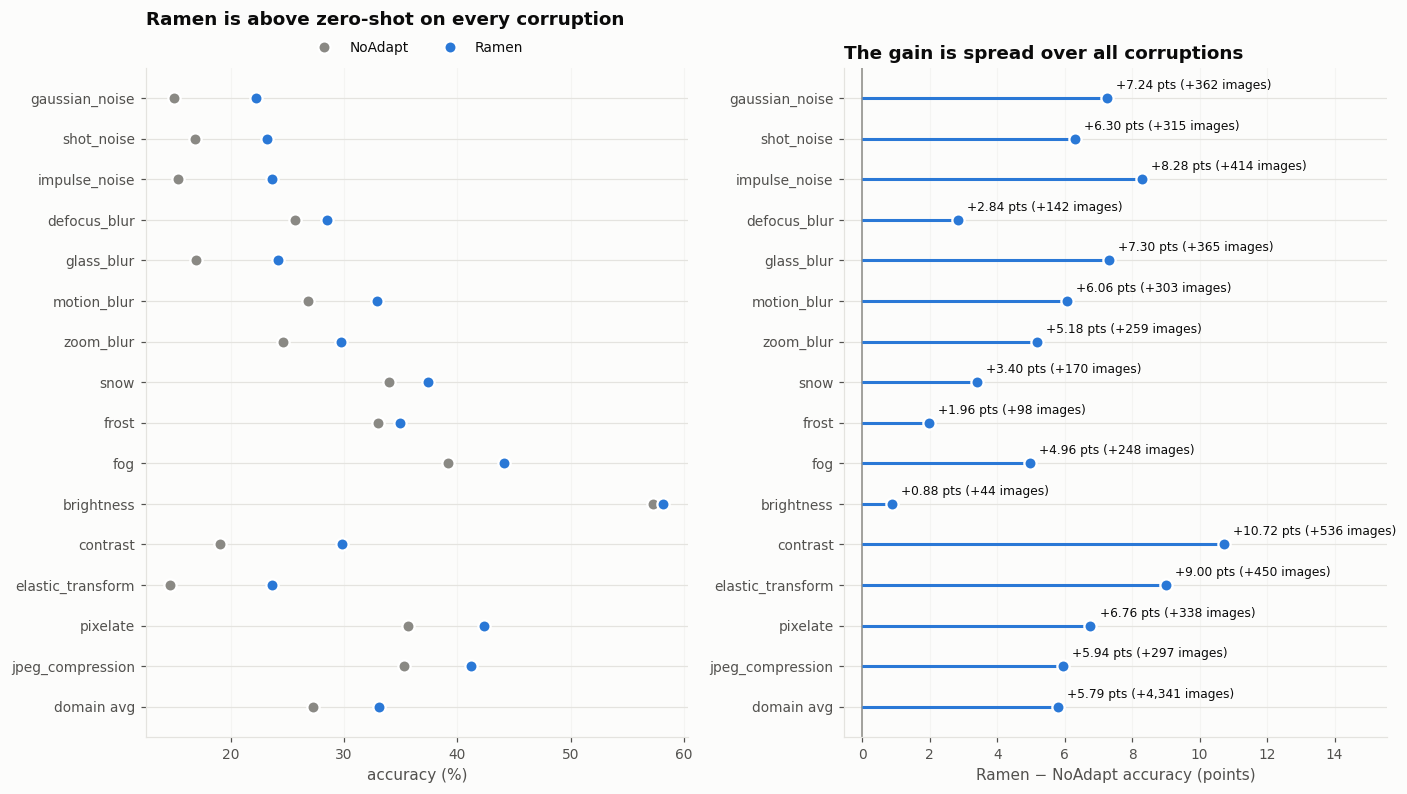

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(exp.change_table('Ramen', by=BY)) + 2.2))
exp.plot_accuracy(['NoAdapt', 'Ramen'], by=BY, ax=axes[0])
axes[0].set_title('Ramen is above zero-shot on every corruption', loc='left', pad=28)
exp.plot_gain('Ramen', 'NoAdapt', by=BY, ax=axes[1])
axes[1].set_title('The gain is spread over all corruptions', loc='left')
fig.tight_layout()

### 4c. Seed 0, over the stream

The gain over zero-shot along the stream (rolling window of 2,000 images, pooled over domains).

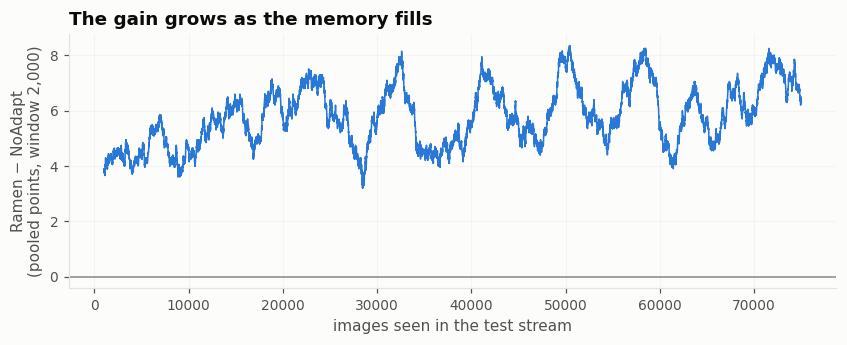

In [7]:
ax = exp.plot_stream_gain('Ramen', 'NoAdapt', window=2000)
ax.set_title('The gain grows as the memory fills', loc='left');

### 4d. Seeds 0–4: the noise floor

Ramen's domain-averaged accuracy for each seed (the stream order changes, the data and model do not).

In [8]:
seeds = seed_table(DATASET, names=('Ramen',))
floor = noise_floor(seeds['Ramen'])
print(f"Ramen over seeds 0-4: {seeds['Ramen'].mean():.2f} ± {seeds['Ramen'].std():.2f}, "
      f"range {seeds['Ramen'].max() - seeds['Ramen'].min():.3f} pts -> noise floor = 2 x range = {floor:.2f} pts")
noadapt = domain_avg(exp.results['NoAdapt'])
seeds.assign(**{'vs NoAdapt (pts)': (seeds['Ramen'] - noadapt).round(2)}).round(2)

Ramen over seeds 0-4: 33.03 ± 0.10, range 0.265 pts -> noise floor = 2 x range = 0.53 pts


,Ramen,vs NoAdapt (pts)
seed,,
0,33.08,5.79
1,33.17,5.88
2,33.02,5.73
3,32.91,5.62
4,32.96,5.67


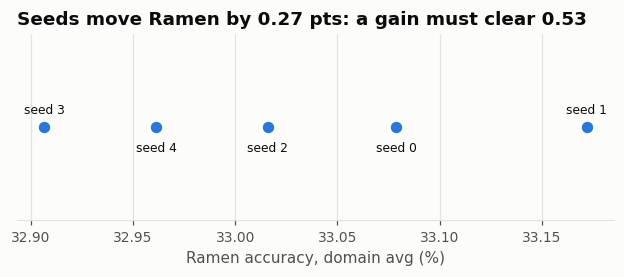

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.plot(seeds['Ramen'], [0] * len(seeds), 'o', ms=9, color='#2a78d6', mec='white', mew=1.5)
for s, v in seeds['Ramen'].items():
    ax.annotate(f'seed {s}', (v, 0), xytext=(0, 9 if s % 2 else -16), textcoords='offset points', ha='center', fontsize=8)
ax.set_yticks([]); ax.spines['left'].set_visible(False)
ax.set_xlabel('Ramen accuracy, domain avg (%)')
ax.set_title(f'Seeds move Ramen by {seeds.Ramen.max() - seeds.Ramen.min():.2f} pts: a gain must clear {floor:.2f}', loc='left');

## 5. Interpretation

- **Ramen beats zero-shot by +5.79 points** (27.29 → 33.08, seed 0), +4,341 of 75,000 images. Ramen changes
  52.5% of predictions: 7,205 images fixed and 2,864 broken. Most changes are wrong → wrong, as on DomainNet, but the
  fixed:broken ratio is better (2.5:1 against 2.0:1).
- **Unlike DomainNet, the gain is spread out**: every corruption gains, from +0.88 (brightness, the easiest, 57.3% zero-shot)
  to +10.72 (contrast). No corruption carries more than 12.3% of the net gain (contrast, net +536). The corruptions zero-shot
  finds hardest (elastic, the three noises, glass blur, all ≤ 17% zero-shot) are among the largest gains, next to contrast.
- **Seeds**: 32.91–33.17 over seeds 0–4, so the **noise floor is 0.53 points**, about 5× DomainNet's. The stream is 8×
  shorter and a 1,000-class memory with capacity 75 is much sparser, so the order matters more. A true-label filing
  change must move ImageNet-C by more than 0.53 to count.
- **The gain grows along the stream** (pooled gain over zero-shot by thirds of the stream, mean over seeds 0–4):
  +5.0 in the first 25,000 images, +6.2 in the last 25,000, higher at the end on 5 of 5 seeds. With 1,000 class
  queues of 75 entries, the memory takes much of the stream to fill. DomainNet's gain is flat by thirds (1.7 points throughout).
- **What to expect next.** `RamenOracle file_true` gave **−0.71** vs Ramen on ImageNet-C seed 0 (2026-10-23), below the
  floor. The smoke subset here points the same way (−0.50 on 3,000 images). The full `true_label` run is the next step.
- Caveat: per-corruption numbers are seed 0 only.

## 6. Glossary

| Term | Meaning |
|---|---|
| NoAdapt | CLIP zero-shot classifier, no test-time adaptation |
| Ramen | Test-time adaptation with a per-class memory of (feature, own entropy gradient, entropy). Each image takes one signSGD step on gradients retrieved from the memory, predicts, and the weights are reset |
| queue / filing | Ramen's memory is one fixed-size queue per class; *filing* = choosing which queue a new image is written to (zero-shot prediction in Ramen) |
| true-label filing (`true_label`) | Oracle: file each image under its true class. Uses ground truth, so it is an upper bound, not a method |
| `zero_shot_filing` | `RamenTrueLabel` with filing by zero-shot prediction, which must equal Ramen (sanity check) |
| domain | A part of the stream with one kind of shift: a DomainNet domain, an ImageNet-C corruption; EuroSAT has one |
| domain-averaged accuracy | Mean of the per-domain accuracies (headline convention) |
| pooled accuracy | Correct images / all images |
| fixed / broken | Image wrong under NoAdapt and right under the run / right under NoAdapt and wrong under the run |
| seed | Sets the stream order; NoAdapt does not depend on it |
| noise floor | 2 × (max − min) of the baseline's accuracy over seeds 0–4; a gain must exceed it to count |
| mixed stream | All domains shuffled together into one test stream |